<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/pinn_pendulum_damping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Finding rusty pivot damping using 2 hidden layer PINN.

<>:178: SyntaxWarning: invalid escape sequence '\m'
<>:178: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3684/3325479995.py:178: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(t_plot, theta_pred, 'r-', linewidth=3, alpha=0.9, label=f'PINN (Discovered $\mu$={final_mu:.4f})')


 Starting Inverse PINN: Discovering Rusty Friction


/tmp/ipykernel_3684/3325479995.py:147: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Iteration  200 | Loss: 6.19907 | Discovered Friction (mu): 0.2348
Iteration  400 | Loss: 2.95544 | Discovered Friction (mu): 0.2200
Iteration  600 | Loss: 0.03513 | Discovered Friction (mu): 0.2176
Iteration  800 | Loss: 0.01952 | Discovered Friction (mu): 0.2046
Iteration 1000 | Loss: 0.01420 | Discovered Friction (mu): 0.1901
Iteration 1200 | Loss: 0.00958 | Discovered Friction (mu): 0.1536
Iteration 1400 | Loss: 0.00788 | Discovered Friction (mu): 0.1499
Iteration 1600 | Loss: 0.00559 | Discovered Friction (mu): 0.1248
Iteration 1800 | Loss: 0.00498 | Discovered Friction (mu): 0.1203
Iteration 2000 | Loss: 0.00475 | Discovered Friction (mu): 0.1217
Iteration 2200 | Loss: 0.00333 | Discovered Friction (mu): 0.1464
Iteration 2400 | Loss: 0.00194 | Discovered Friction (mu): 0.1669
Iteration 2600 | Loss: 0.00157 | Discovered Friction (mu): 0.1827
Iteration 2800 | Loss: 0.00130 | Discovered Friction (mu): 0.1609
Iteration 3000 | Loss: 0.00112 | Discovered Friction (mu): 0.1475
Iteration 

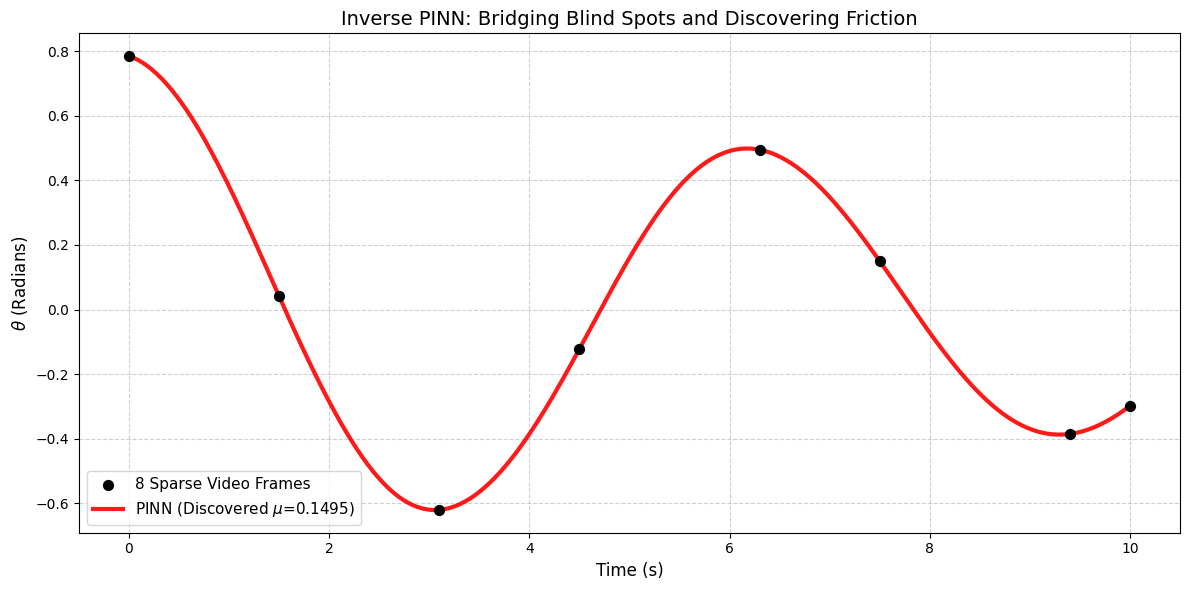

In [1]:
import jax
import jax.numpy as jnp
from jax import jit, value_and_grad, grad, vmap

# Force JAX to use 64-bit precision to match SciPy and prevent crashes
jax.config.update("jax_enable_x64", True)

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import time

# ==========================================
# 1. The Sparse Video Data (Rusty Hinge)
# ==========================================
# Only 8 data points scattered across 10 seconds (massive blind spots)
t_data = np.array([0.0, 1.5, 3.1, 4.5, 6.3, 7.5, 9.4, 10.0]).reshape(-1, 1)

theta_data = np.array([0.785, 0.041, -0.620, -0.122, 0.495, 0.150, -0.385, -0.298]).reshape(-1, 1)

# Dense collocation points for the physics loss constraint
t_domain = jnp.linspace(0, 10, 400).reshape(-1, 1)

# ==========================================
# 2. 2-Layer PINN Architecture
# ==========================================
def unpack_weights(params, H):
    """
    Reconstructs the weight matrices from the flat 1D array.
    CRITICAL: We extract the unknown damping parameter (mu) at the very end!
    """
    idx = 0
    W1 = params[idx : idx+H].reshape(1, H); idx += H
    b1 = params[idx : idx+H].reshape(1, H); idx += H
    W2 = params[idx : idx+H*H].reshape(H, H); idx += H*H
    b2 = params[idx : idx+H].reshape(1, H); idx += H
    W3 = params[idx : idx+H].reshape(H, 1); idx += H
    b3 = params[idx : idx+1].reshape(1, 1); idx += 1

    # Extract the unknown friction parameter!
    mu_param = params[idx]

    return W1, b1, W2, b2, W3, b3, mu_param

def pack_weights(W1, b1, W2, b2, W3, b3, mu_param):
    """Flattens weights and the unknown mu into a 1D array."""
    return np.concatenate([
        W1.flatten(), b1.flatten(),
        W2.flatten(), b2.flatten(),
        W3.flatten(), b3.flatten(),
        mu_param.flatten() # Appended to the very end
    ])

def predict_theta(params, t_scalar, H):
    # We unpack, but ignore mu here because the feed-forward network
    # prediction function doesn't care about the friction rules.
    W1, b1, W2, b2, W3, b3, _ = unpack_weights(params, H)

    # Scale time to keep the math stable
    t_max = 10.0
    tau = t_scalar / t_max

    a1 = jnp.tanh(jnp.dot(tau, W1) + b1)
    a2 = jnp.tanh(jnp.dot(a1, W2) + b2)
    theta = jnp.dot(a2, W3) + b3
    return theta[0, 0]

# ==========================================
# 3. Universal AutoDiff Physics Builder
# ==========================================
# Ask JAX to dynamically build the derivatives for velocity AND acceleration!
predict_velocity = grad(predict_theta, argnums=1)
predict_acceleration = grad(predict_velocity, argnums=1)

# Vectorize the scalar functions so they can run over massive arrays of time
vmap_theta = vmap(predict_theta, in_axes=(None, 0, None))
vmap_velocity = vmap(predict_velocity, in_axes=(None, 0, None))
vmap_acceleration = vmap(predict_acceleration, in_axes=(None, 0, None))

def compute_loss(params, t_domain, t_data, theta_data, H):
    t_flat = t_domain.flatten()
    t_data_flat = t_data.flatten()

    # Unpack the dynamically changing mu
    _, _, _, _, _, _, mu_param = unpack_weights(params, H)

    # 1. Physics Loss (L_ODE)
    theta_pred_ode = vmap_theta(params, t_flat, H)
    velocity_pred_ode = vmap_velocity(params, t_flat, H)
    acceleration_pred_ode = vmap_acceleration(params, t_flat, H)

    # The Rusty Hinge Equation: acceleration + (mu * velocity) + sin(theta) = 0
    # The network is forced to find what 'mu' explains the energy decay!
    residual = acceleration_pred_ode + (mu_param * velocity_pred_ode) + jnp.sin(theta_pred_ode)
    loss_ode = jnp.mean(residual**2)

    # 2. Data Loss (L_Data)
    # This anchors the curve to the 8 sparse video frames
    theta_pred_data = vmap_theta(params, t_data_flat, H)
    loss_data = jnp.mean((theta_pred_data - theta_data.flatten())**2)

    # The Goldilocks Balance (2000x) strongly prioritizes hitting the frames
    # while using the ODE loss to beautifully bridge the blind spots!
    return loss_ode + (2000.0 * loss_data)

loss_and_grad = jit(value_and_grad(compute_loss), static_argnums=(4,))

def scipy_objective(params, t_domain, t_data, theta_data, H):
    loss, grads = loss_and_grad(params, t_domain, t_data, theta_data, H)
    return float(loss), np.array(grads)

# ==========================================
# 4. Training Setup
# ==========================================
H = 32
np.random.seed(42)

# W1 scaled by 10.0 to break Spectral Bias for a 10-second domain
W1 = np.random.randn(1, H) * 10.0
b1 = np.zeros((1, H))
W2 = np.random.randn(H, H) * np.sqrt(2.0 / (H + H))
b2 = np.zeros((1, H))
W3 = np.random.randn(H, 1) * np.sqrt(2.0 / (H + 1))
b3 = np.zeros((1, 1))

# Initialize our unknown Friction (mu) guess!
# We assume it is completely frictionless (0.0) at the start.
mu_init = np.array([0.0])

current_weights = pack_weights(W1, b1, W2, b2, W3, b3, mu_init)

progress = {'iterations': 0}

def monitor_progress(xk):
    progress['iterations'] += 1
    if progress['iterations'] % 200 == 0:
        current_loss = compute_loss(xk, t_domain, t_data, theta_data, H)
        # Extract the current guess for friction right from the end of the array!
        current_mu = xk[-1]
        print(f"Iteration {progress['iterations']:4d} | Loss: {float(current_loss):.5f} | Discovered Friction (mu): {current_mu:.4f}")

print("==================================================")
print(" Starting Inverse PINN: Discovering Rusty Friction")
print("==================================================")
start_time = time.time()

res = minimize(
    fun=scipy_objective,
    x0=current_weights,
    args=(t_domain, t_data, theta_data, H),
    method='L-BFGS-B',
    jac=True,
    callback=monitor_progress,
    options={'maxiter': 5000, 'maxfun': 50000, 'disp': False}
)

final_weights = res.x
_, _, _, _, _, _, final_mu = unpack_weights(final_weights, H)

elapsed = time.time() - start_time
print(f"\nTraining Complete in {elapsed:.2f}s!")
print(f"Final Loss: {res.fun:.6f}")
print(f">>> FINAL DISCOVERED FRICTION (mu): {final_mu:.4f} <<<")
print(f"(Expected Friction is ~0.15)")

# ==========================================
# 5. Evaluation and Plotting
# ==========================================
t_plot = np.array(t_domain).flatten()
theta_pred = np.array(vmap_theta(final_weights, t_plot, H))

plt.figure(figsize=(12, 6))

# Plot the Sparse Video Data
plt.scatter(t_data, theta_data, color='black', label='8 Sparse Video Frames', zorder=5, s=50)

# Plot the PINN's Continuous Prediction bridging the massive gaps
plt.plot(t_plot, theta_pred, 'r-', linewidth=3, alpha=0.9, label=f'PINN (Discovered $\mu$={final_mu:.4f})')

plt.title("Inverse PINN: Bridging Blind Spots and Discovering Friction", fontsize=14)
plt.xlabel("Time (s)", fontsize=12)
plt.ylabel("$\\theta$ (Radians)", fontsize=12)
plt.legend(loc='lower left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()